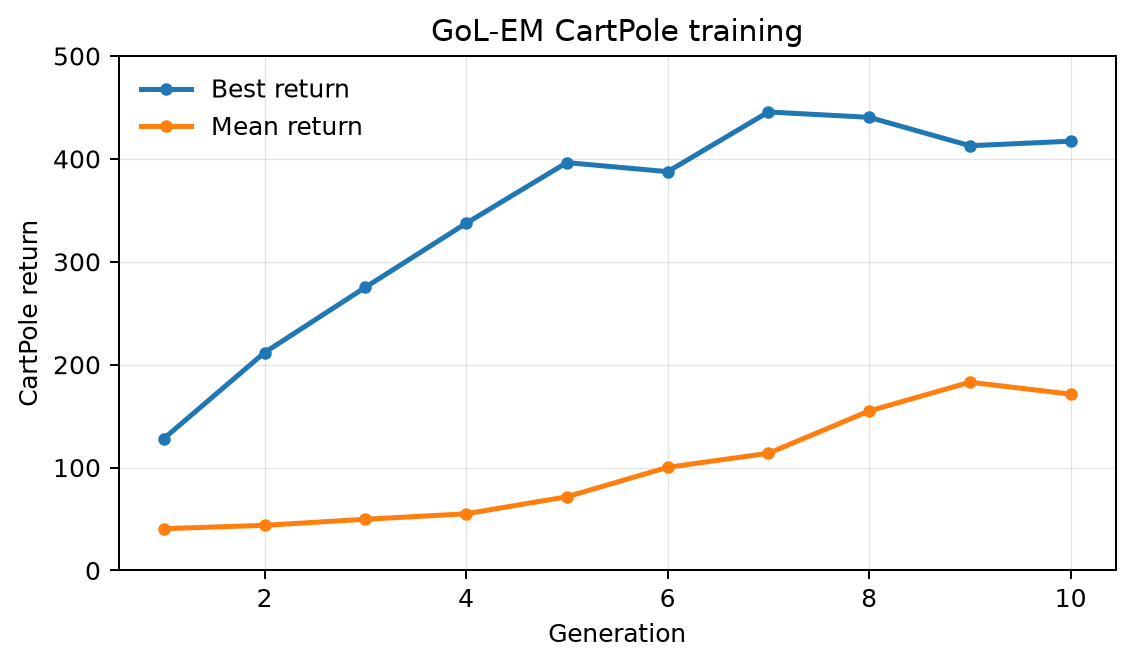

History: C:\Users\Admin\Downloads\em-exp-gol-cem1d-main\gol-cp\runs\run_20261126_174520\history.csv
Saved to: C:\Users\Admin\Downloads\em-exp-gol-cem1d-main\gol-cp\runs\run_20261126_174520\gol_cp_return_curve.png


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path


def latest_run_file(filename):
    cwd = Path.cwd().resolve()
    roots = (cwd, *cwd.parents)
    candidates = {
        path.resolve()
        for root in roots
        for runs_dir in (root / "runs", root / "gol-cp" / "runs")
        if runs_dir.is_dir()
        for path in runs_dir.glob(f"run_*/{filename}")
        if path.is_file()
    }
    if not candidates:
        raise FileNotFoundError(
            f"Could not find {filename} inside any runs/run_*/ folder from {cwd}"
        )
    return max(candidates, key=lambda path: path.stat().st_mtime)


history_path = latest_run_file("history.csv")
df = pd.read_csv(history_path)

fig, ax = plt.subplots(figsize=(6.4, 3.8), dpi=180)

ax.plot(df["gen"], df["best_cp"], marker="o", linewidth=2, markersize=4, label="Best return")
ax.plot(df["gen"], df["mean_cp"], marker="o", linewidth=2, markersize=4, label="Mean return")

ax.set_xlabel("Generation")
ax.set_ylabel("CartPole return")
ax.set_title("GoL-EM CartPole training")
ax.set_ylim(0, 500)
ax.grid(True, linewidth=0.5, alpha=0.35)
ax.legend(frameon=False)
fig.tight_layout()

out_path = history_path.parent / "gol_cp_return_curve.png"
fig.savefig(out_path, bbox_inches="tight")
plt.show()

print("History:", history_path)
print("Saved to:", out_path)


In [2]:
from pathlib import Path
import imageio.v2 as imageio
import matplotlib.pyplot as plt


def latest_run_file(filename):
    cwd = Path.cwd().resolve()
    roots = (cwd, *cwd.parents)
    candidates = {
        path.resolve()
        for root in roots
        for runs_dir in (root / "runs", root / "gol-cp" / "runs")
        if runs_dir.is_dir()
        for path in runs_dir.glob(f"run_*/{filename}")
        if path.is_file()
    }
    if not candidates:
        raise FileNotFoundError(
            f"Could not find {filename} inside any runs/run_*/ folder from {cwd}"
        )
    return max(candidates, key=lambda path: path.stat().st_mtime)


video_path = latest_run_file("gol.mp4")

offset_sec = 6.0
times_sec = [0, 0.2, 0.5, 1, 2, 4, 8]  # relative times after offset

reader = imageio.get_reader(video_path)
meta = reader.get_meta_data()
fps = meta["fps"]
n_frames = reader.count_frames()

frame_ids = [int(round((offset_sec + t) * fps)) for t in times_sec]
frame_ids = [i for i in frame_ids if i < n_frames]

out_dir = video_path.parent / f"gol_frames_offset_{offset_sec:g}s"
out_dir.mkdir(parents=True, exist_ok=True)

for idx in frame_ids:
    frame = reader.get_data(idx)

    fig, ax = plt.subplots(figsize=(4, 4), dpi=180)
    ax.imshow(frame)
    ax.set_title(f"frame {idx}")
    ax.axis("off")
    fig.tight_layout()

    out_path = out_dir / f"frame_{idx:06d}.png"
    fig.savefig(out_path, bbox_inches="tight")
    plt.close(fig)

reader.close()

print("Video:", video_path)
print("fps:", fps)
print("saved frames:", frame_ids)
print("out_dir:", out_dir)


Video: C:\Users\Admin\Downloads\em-exp-gol-cem1d-main\gol-cp\runs\run_20261126_174520\gol.mp4
fps: 48.0
saved frames: [288, 298, 312, 336, 384, 480, 672]
out_dir: C:\Users\Admin\Downloads\em-exp-gol-cem1d-main\gol-cp\runs\run_20261126_174520\gol_frames_offset_6s
